<a href="https://colab.research.google.com/github/jasmindamia/UTP-MACHINE-LEARNING/blob/main/lab03_model_families.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:


import os

print("Current directory:", os.getcwd())
print("\nFiles and folders available:")

for item in os.listdir("/content"):
    print(item)


Current directory: /content

Files and folders available:
.config
sample_data


In [3]:
!git clone https://github.com/jasmindamia/UTP-MACHINE-LEARNING.git

Cloning into 'UTP-MACHINE-LEARNING'...
remote: Enumerating objects: 24, done.
remote: Counting objects: 100% (24/24), done.
remote: Compressing objects: 100% (20/20), done.
remote: Total 24 (delta 3), reused 23 (delta 2), pack-reused 0 (from 0)
Receiving objects: 100% (24/24), 1.39 MiB | 8.45 MiB/s, done.
Resolving deltas: 100% (3/3), done.


In [5]:

import os

PROJECT_ROOT = "/content/UTP-MACHINE-LEARNING"

print("Repository contents:")
for item in os.listdir(PROJECT_ROOT):
    print(item)


Repository contents:
all_datasets
results
.DS_Store
all_experiments
.gitignore
.git


In [6]:

from pathlib import Path

PROJECT_ROOT = Path("/content/UTP-MACHINE-LEARNING")

print("Searching for CSV datasets...\n")

for file in PROJECT_ROOT.rglob("*.csv"):
    print(file.relative_to(PROJECT_ROOT))


Searching for CSV datasets...

all_datasets/credit_card_fraud_dataset.csv
all_datasets/ames_housing_dataset.csv
all_datasets/breast_cancer_dataset.csv
all_datasets/mall_customers_dataset.csv
all_datasets/medical_cost_personal_dataset.csv
all_datasets/bike_sharing_dataset_day.csv
all_datasets/titanic_dataset.csv
all_datasets/bike_sharing_dataset_hour.csv
all_datasets/red_wine_quality_dataset.csv
all_datasets/student_performance_dataset.csv
all_datasets/heart_failure_dataset.csv


In [7]:

from pathlib import Path

# Set the project directory
PROJECT_ROOT = Path("/content/UTP-MACHINE-LEARNING")

# Set the dataset and model folders
DATA = PROJECT_ROOT / "all_datasets"
MODELS = PROJECT_ROOT / "models"

# Create the models folder if it doesn't exist
MODELS.mkdir(exist_ok=True)

# Verify the required datasets
required_files = [
    "breast_cancer_dataset.csv",
    "titanic_dataset.csv",
    "ames_housing_dataset.csv",
    "red_wine_quality_dataset.csv"
]

for filename in required_files:
    file_path = DATA / filename
    print(f"{filename}: {'FOUND' if file_path.exists() else 'NOT FOUND'}")

print("\nProject setup complete!")
print("Dataset folder:", DATA)
print("Model folder:", MODELS)


breast_cancer_dataset.csv: FOUND
titanic_dataset.csv: FOUND
ames_housing_dataset.csv: FOUND
red_wine_quality_dataset.csv: FOUND

Project setup complete!
Dataset folder: /content/UTP-MACHINE-LEARNING/all_datasets
Model folder: /content/UTP-MACHINE-LEARNING/models


In [8]:

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.inspection import DecisionBoundaryDisplay, permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    mean_absolute_error,
    mean_squared_error,
    roc_auc_score
)
from sklearn.model_selection import (
    GridSearchCV,
    KFold,
    StratifiedKFold,
    cross_val_score,
    train_test_split
)
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree

print("All libraries imported successfully!")


All libraries imported successfully!


In [9]:

# Load the breast cancer dataset
cancer = pd.read_csv(DATA / "breast_cancer_dataset.csv")

# Inspect the dataset
print("Dataset shape:", cancer.shape)
print("\nFirst five rows:")
display(cancer.head())

print("\nColumn names:")
print(cancer.columns.tolist())

print("\nDiagnosis counts:")
print(cancer["diagnosis"].value_counts())


Dataset shape: (569, 33)

First five rows:


,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,NaN



Column names:
['id', 'diagnosis', 'radius_mean', 'texture_mean', 'perimeter_mean', 'area_mean', 'smoothness_mean', 'compactness_mean', 'concavity_mean', 'concave points_mean', 'symmetry_mean', 'fractal_dimension_mean', 'radius_se', 'texture_se', 'perimeter_se', 'area_se', 'smoothness_se', 'compactness_se', 'concavity_se', 'concave points_se', 'symmetry_se', 'fractal_dimension_se', 'radius_worst', 'texture_worst', 'perimeter_worst', 'area_worst', 'smoothness_worst', 'compactness_worst', 'concavity_worst', 'concave points_worst', 'symmetry_worst', 'fractal_dimension_worst', 'Unnamed: 32']

Diagnosis counts:
diagnosis
B    357
M    212
Name: count, dtype: int64


In [10]:

# Remove unnecessary columns and prepare the target
X_c = cancer.drop(
    columns=["id", "diagnosis", "Unnamed: 32"],
    errors="ignore"
)

# Convert diagnosis into numerical labels:
# M (malignant) = 1
# B (benign) = 0
y_c = (cancer["diagnosis"] == "M").astype(int)

print("Features shape:", X_c.shape)
print("Target shape:", y_c.shape)

print("\nTarget distribution:")
print(y_c.value_counts().rename(index={0: "Benign (0)", 1: "Malignant (1)"}))

print("\nMissing values in features:", X_c.isna().sum().sum())


Features shape: (569, 30)
Target shape: (569,)

Target distribution:
diagnosis
Benign (0)       357
Malignant (1)    212
Name: count, dtype: int64

Missing values in features: 0


In [11]:

from sklearn.model_selection import train_test_split

Xc_train, Xc_valid, yc_train, yc_valid = train_test_split(
    X_c,
    y_c,
    test_size=0.25,
    random_state=42,
    stratify=y_c
)

print("Training features:", Xc_train.shape)
print("Validation features:", Xc_valid.shape)

print("\nTraining diagnosis distribution:")
print(yc_train.value_counts())

print("\nValidation diagnosis distribution:")
print(yc_valid.value_counts())


Training features: (426, 30)
Validation features: (143, 30)

Training diagnosis distribution:
diagnosis
0    267
1    159
Name: count, dtype: int64

Validation diagnosis distribution:
diagnosis
0    90
1    53
Name: count, dtype: int64


k= 1 cross-validated ROC AUC = 0.946
k= 3 cross-validated ROC AUC = 0.984
k= 5 cross-validated ROC AUC = 0.985
k= 7 cross-validated ROC AUC = 0.987
k=11 cross-validated ROC AUC = 0.988
k=21 cross-validated ROC AUC = 0.988

Selected k: 11


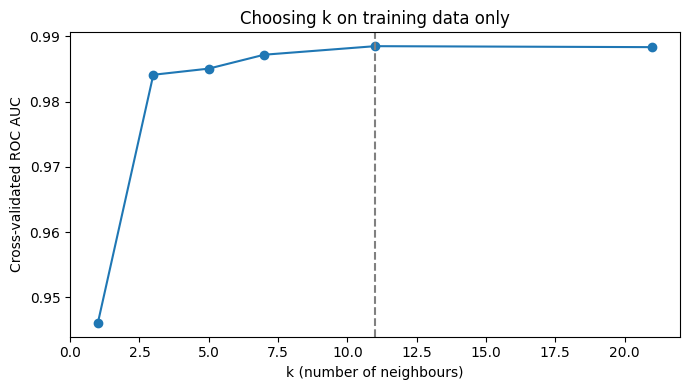

In [12]:

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

k_values = [1, 3, 5, 7, 11, 21]
cv_scores = {}

for k in k_values:
    candidate = Pipeline([
        ("scale", StandardScaler()),
        ("model", KNeighborsClassifier(
            n_neighbors=k,
            weights="distance"
        ))
    ])

    scores = cross_val_score(
        candidate,
        Xc_train,
        yc_train,
        cv=cv,
        scoring="roc_auc"
    )

    cv_scores[k] = scores.mean()

    print(
        f"k={k:2d} cross-validated ROC AUC = "
        f"{scores.mean():.3f}"
    )

best_k = max(cv_scores, key=cv_scores.get)

print("\nSelected k:", best_k)

plt.figure(figsize=(7, 4))
plt.plot(
    k_values,
    [cv_scores[k] for k in k_values],
    marker="o"
)
plt.axvline(best_k, linestyle="--", color="grey")
plt.xlabel("k (number of neighbours)")
plt.ylabel("Cross-validated ROC AUC")
plt.title("Choosing k on training data only")
plt.tight_layout()
plt.show()


In [13]:

# Define the two models
models = {
    "KNN": Pipeline([
        ("scale", StandardScaler()),
        ("model", KNeighborsClassifier(
            n_neighbors=best_k,
            weights="distance"
        )),
    ]),
    "GaussianNB": Pipeline([
        ("scale", StandardScaler()),
        ("model", GaussianNB()),
    ]),
}

# Train and evaluate both models
for name, model in models.items():
    model.fit(Xc_train, yc_train)

    pred = model.predict(Xc_valid)
    prob_c = model.predict_proba(Xc_valid)[:, 1]

    print(
        f"{name:10s} "
        f"accuracy={accuracy_score(yc_valid, pred):.3f} "
        f"roc_auc={roc_auc_score(yc_valid, prob_c):.3f}"
    )


KNN        accuracy=0.958 roc_auc=0.986
GaussianNB accuracy=0.944 roc_auc=0.992


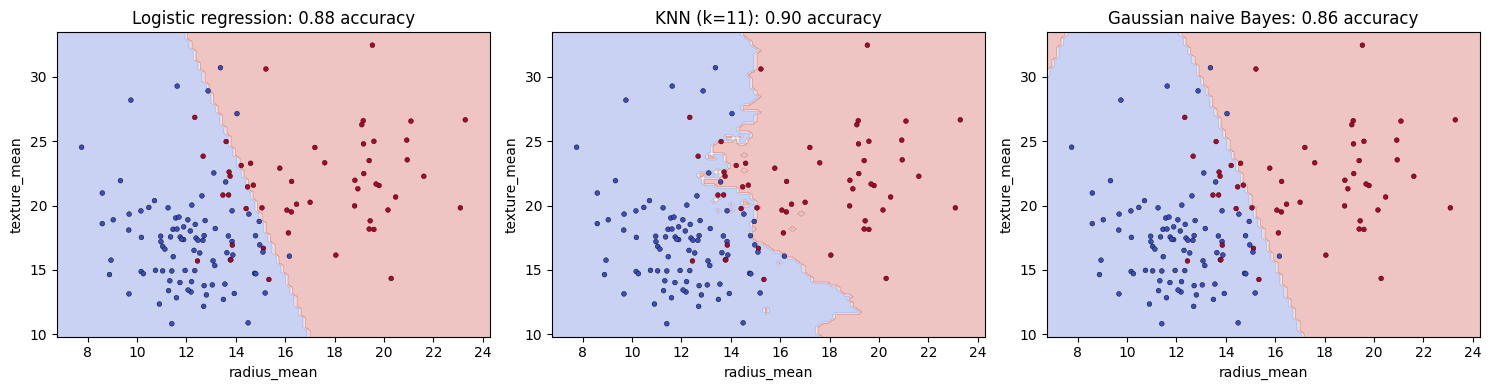

In [14]:

two = ["radius_mean", "texture_mean"]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

boundary_models = [
    ("Logistic regression", LogisticRegression(max_iter=2000)),
    (
        f"KNN (k={best_k})",
        KNeighborsClassifier(
            n_neighbors=best_k,
            weights="distance"
        )
    ),
    ("Gaussian naive Bayes", GaussianNB()),
]

for ax, (name, estimator) in zip(axes, boundary_models):
    small = Pipeline([
        ("scale", StandardScaler()),
        ("model", estimator)
    ])

    small.fit(Xc_train[two], yc_train)

    DecisionBoundaryDisplay.from_estimator(
        small,
        Xc_valid[two],
        ax=ax,
        alpha=0.3,
        response_method="predict",
        cmap="coolwarm"
    )

    ax.scatter(
        Xc_valid[two[0]],
        Xc_valid[two[1]],
        c=yc_valid,
        cmap="coolwarm",
        s=12,
        edgecolor="k",
        linewidth=0.3
    )

    accuracy = accuracy_score(
        yc_valid,
        small.predict(Xc_valid[two])
    )

    ax.set_title(f"{name}: {accuracy:.2f} accuracy")
    ax.set_xlabel("radius_mean")
    ax.set_ylabel("texture_mean")

plt.tight_layout()
plt.show()


In [15]:
#--PART B--
# Load the Titanic dataset
titanic = pd.read_csv(DATA / "titanic_dataset.csv")

print("Dataset shape:", titanic.shape)

print("\nFirst five rows:")
display(titanic.head())

print("\nColumn names:")
print(titanic.columns.tolist())

print("\nMissing values:")
print(titanic.isna().sum())

print("\nSurvival counts:")
print(titanic["Survived"].value_counts())


Dataset shape: (891, 12)

First five rows:


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S



Column names:
['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked']

Missing values:
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

Survival counts:
Survived
0    549
1    342
Name: count, dtype: int64


In [16]:
# Select the features used to predict survival
features = ["Pclass", "Sex", "Age", "SibSp", "Parch", "Fare", "Embarked"]

# Separate input features (X) and target (y)
X_t = titanic[features]
y_t = titanic["Survived"]

# Separate numerical and categorical features
t_num = ["Age", "SibSp", "Parch", "Fare"]
t_cat = ["Pclass", "Sex", "Embarked"]

# Split into training and validation sets
Xt_train, Xt_valid, yt_train, yt_valid = train_test_split(
    X_t,
    y_t,
    test_size=0.25,
    random_state=42,
    stratify=y_t
)

print("Training features shape:", Xt_train.shape)
print("Validation features shape:", Xt_valid.shape)

print("\nTraining survival distribution:")
print(yt_train.value_counts())

print("\nValidation survival distribution:")
print(yt_valid.value_counts())

Training features shape: (668, 7)
Validation features shape: (223, 7)

Training survival distribution:
Survived
0    412
1    256
Name: count, dtype: int64

Validation survival distribution:
Survived
0    137
1     86
Name: count, dtype: int64


In [17]:
# Preprocessing for numerical features
# Fill missing values with the median
num_imputer = SimpleImputer(strategy="median")

# Preprocessing for categorical features
# Fill missing values with the most frequent value,
# then convert categories into numerical columns
cat_preprocessor = Pipeline([
    ("impute", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both preprocessing methods
tree_preprocess = ColumnTransformer([
    ("num", num_imputer, t_num),
    ("cat", cat_preprocessor, t_cat)
])

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [18]:
# Create the decision tree model
tree = Pipeline([
    ("preprocess", tree_preprocess),
    ("tree", DecisionTreeClassifier(
        max_depth=4,
        min_samples_leaf=12,
        random_state=42
    ))
])

# Train the model
tree.fit(Xt_train, yt_train)

# Evaluate accuracy on training and validation data
train_predictions = tree.predict(Xt_train)
valid_predictions = tree.predict(Xt_valid)

print("Training accuracy:",
      round(accuracy_score(yt_train, train_predictions), 3))

print("Validation accuracy:",
      round(accuracy_score(yt_valid, valid_predictions), 3))

Training accuracy: 0.843
Validation accuracy: 0.767


In [19]:
# Get feature names after preprocessing
feature_names = list(
    tree.named_steps["preprocess"].get_feature_names_out()
)

# Print the decision rules
print(export_text(
    tree.named_steps["tree"],
    feature_names=feature_names,
    max_depth=3
))

|--- cat__Sex_female <= 0.50
|   |--- num__Age <= 3.50
|   |   |--- class: 1
|   |--- num__Age >  3.50
|   |   |--- cat__Pclass_1 <= 0.50
|   |   |   |--- num__Fare <= 48.09
|   |   |   |   |--- class: 0
|   |   |   |--- num__Fare >  48.09
|   |   |   |   |--- class: 0
|   |   |--- cat__Pclass_1 >  0.50
|   |   |   |--- num__Age <= 53.00
|   |   |   |   |--- class: 0
|   |   |   |--- num__Age >  53.00
|   |   |   |   |--- class: 0
|--- cat__Sex_female >  0.50
|   |--- cat__Pclass_3 <= 0.50
|   |   |--- num__Fare <= 28.86
|   |   |   |--- num__Age <= 37.00
|   |   |   |   |--- class: 1
|   |   |   |--- num__Age >  37.00
|   |   |   |   |--- class: 1
|   |   |--- num__Fare >  28.86
|   |   |   |--- num__Parch <= 1.50
|   |   |   |   |--- class: 1
|   |   |   |--- num__Parch >  1.50
|   |   |   |   |--- class: 1
|   |--- cat__Pclass_3 >  0.50
|   |   |--- num__Fare <= 7.89
|   |   |   |--- cat__Embarked_S <= 0.50
|   |   |   |   |--- class: 1
|   |   |   |--- cat__Embarked_S >  0.50
|   |

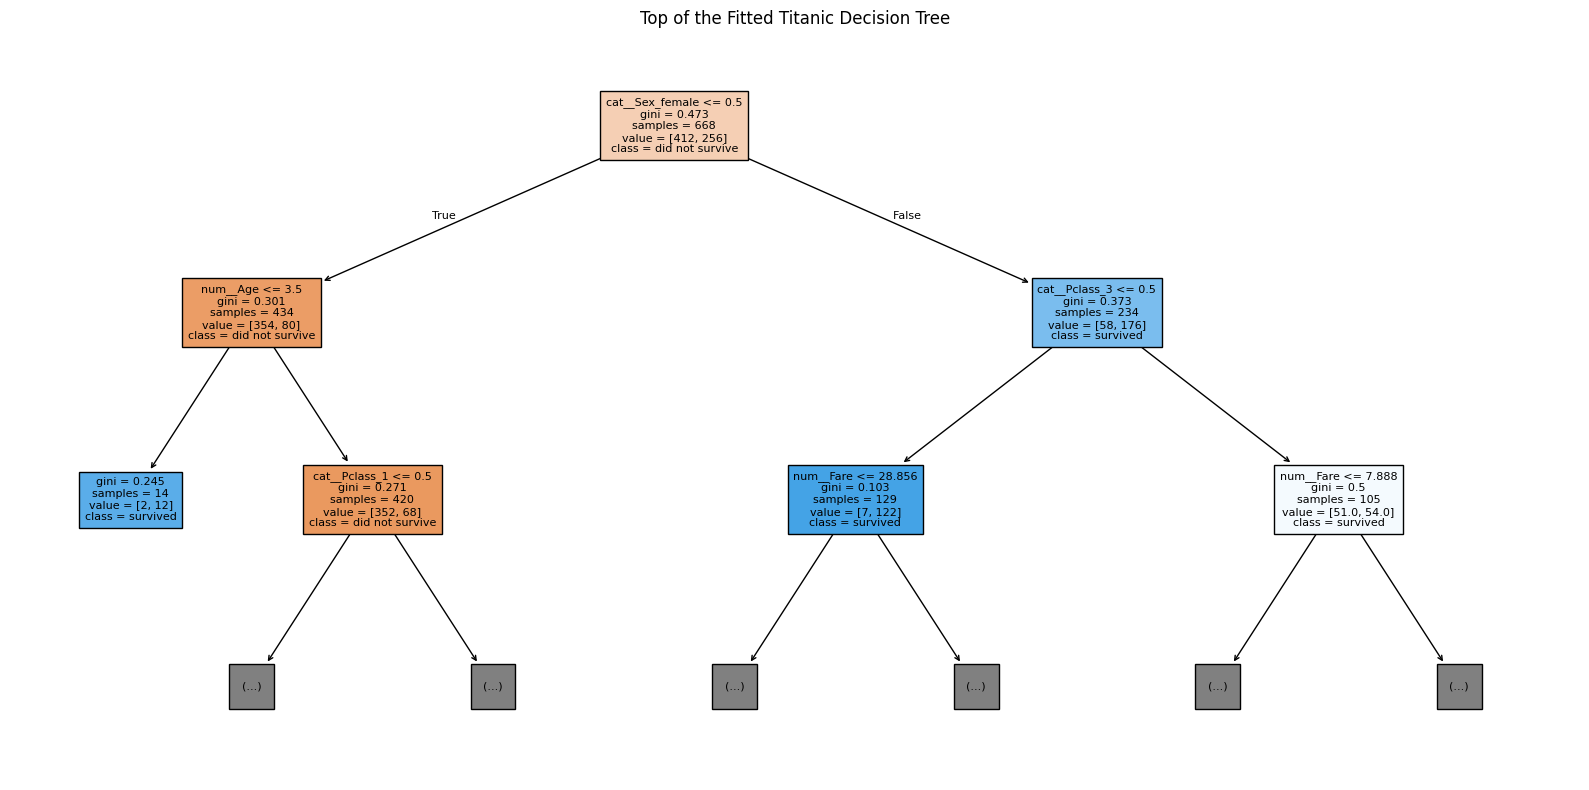

In [20]:
plt.figure(figsize=(16, 8))

plot_tree(
    tree.named_steps["tree"],
    feature_names=feature_names,
    class_names=["did not survive", "survived"],
    max_depth=2,
    filled=True,
    fontsize=8
)

plt.title("Top of the Fitted Titanic Decision Tree")
plt.tight_layout()
plt.show()

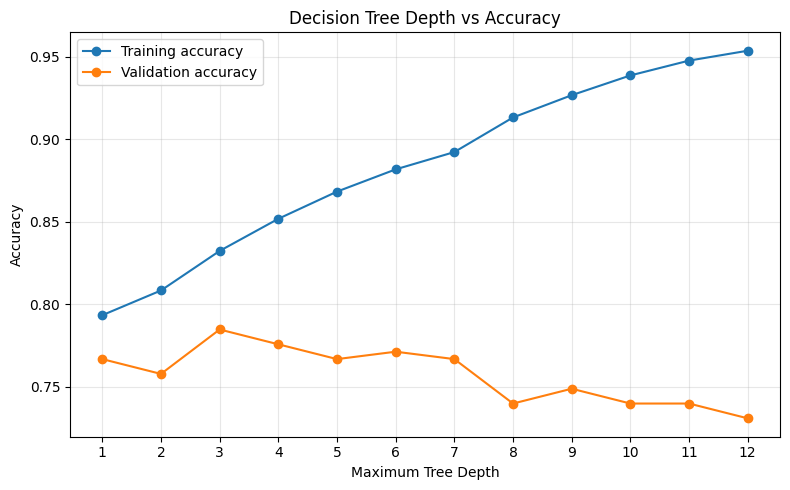

Depth | Training | Validation
    1 |    0.793 |      0.767
    2 |    0.808 |      0.758
    3 |    0.832 |      0.785
    4 |    0.852 |      0.776
    5 |    0.868 |      0.767
    6 |    0.882 |      0.771
    7 |    0.892 |      0.767
    8 |    0.913 |      0.740
    9 |    0.927 |      0.749
   10 |    0.939 |      0.740
   11 |    0.948 |      0.740
   12 |    0.954 |      0.731


In [21]:
depths = list(range(1, 13))
train_acc, valid_acc = [], []

for depth in depths:
    t = Pipeline([
        ("preprocess", tree_preprocess),
        ("tree", DecisionTreeClassifier(
            max_depth=depth,
            random_state=42
        ))
    ])

    t.fit(Xt_train, yt_train)

    train_acc.append(
        accuracy_score(yt_train, t.predict(Xt_train))
    )
    valid_acc.append(
        accuracy_score(yt_valid, t.predict(Xt_valid))
    )

# Plot the results
plt.figure(figsize=(8, 5))
plt.plot(depths, train_acc, marker="o", label="Training accuracy")
plt.plot(depths, valid_acc, marker="o", label="Validation accuracy")

plt.xlabel("Maximum Tree Depth")
plt.ylabel("Accuracy")
plt.title("Decision Tree Depth vs Accuracy")
plt.xticks(depths)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("Depth | Training | Validation")
for d, tr, va in zip(depths, train_acc, valid_acc):
    print(f"{d:5d} | {tr:8.3f} | {va:10.3f}")

In [22]:
#--PART C--

# Load the Ames Housing dataset
ames = pd.read_csv(DATA / "ames_housing_dataset.csv")

print("Dataset shape:", ames.shape)

print("\nFirst five rows:")
display(ames.head())

print("\nTarget column information:")
print(ames["SalePrice"].describe())

print("\nMissing values in target:")
print(ames["SalePrice"].isna().sum())

print("\nData types:")
print(ames.dtypes.value_counts())

Dataset shape: (2930, 82)

First five rows:


,Order,PID,MS SubClass,MS Zoning,Lot Frontage,Lot Area,Street,Alley,Lot Shape,Land Contour,...,Pool Area,Pool QC,Fence,Misc Feature,Misc Val,Mo Sold,Yr Sold,Sale Type,Sale Condition,SalePrice
0,1,526301100,20,RL,141.0,31770,Pave,NaN,IR1,Lvl,...,0,NaN,NaN,NaN,0,5,2010,WD,Normal,215000
1,2,526350040,20,RH,80.0,11622,Pave,NaN,Reg,Lvl,...,0,NaN,MnPrv,NaN,0,6,2010,WD,Normal,105000
2,3,526351010,20,RL,81.0,14267,Pave,NaN,IR1,Lvl,...,0,NaN,NaN,Gar2,12500,6,2010,WD,Normal,172000
3,4,526353030,20,RL,93.0,11160,Pave,NaN,Reg,Lvl,...,0,NaN,NaN,NaN,0,4,2010,WD,Normal,244000
4,5,527105010,60,RL,74.0,13830,Pave,NaN,IR1,Lvl,...,0,NaN,MnPrv,NaN,0,3,2010,WD,Normal,189900



Target column information:
count      2930.000000
mean     180796.060068
std       79886.692357
min       12789.000000
25%      129500.000000
50%      160000.000000
75%      213500.000000
max      755000.000000
Name: SalePrice, dtype: float64

Missing values in target:
0

Data types:
object     43
int64      28
float64    11
Name: count, dtype: int64


In [23]:
# Separate input features and target
X_a = ames.drop(columns=["SalePrice", "Order", "PID"])
y_a = np.log1p(ames["SalePrice"])

# Identify numerical and categorical columns
a_num = X_a.select_dtypes(include=np.number).columns.tolist()
a_cat = X_a.select_dtypes(exclude=np.number).columns.tolist()

print("Feature matrix shape:", X_a.shape)
print("Numerical features:", len(a_num))
print("Categorical features:", len(a_cat))
print("Missing numerical values:", X_a[a_num].isna().sum().sum())
print("Missing categorical values:", X_a[a_cat].isna().sum().sum())

# Preprocess numerical and categorical features
ames_preprocess = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), a_num),
    ("cat", Pipeline([
        ("impute", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False
        ))
    ]), a_cat)
])

print("\nAmes preprocessing pipeline created successfully!")

Feature matrix shape: (2930, 79)
Numerical features: 36
Categorical features: 43
Missing numerical values: 682
Missing categorical values: 15067

Ames preprocessing pipeline created successfully!


In [24]:
# Split into training and validation sets
Xa_train, Xa_valid, ya_train, ya_valid = train_test_split(
    X_a, y_a,
    test_size=0.25,
    random_state=42
)

# Define the models
ames_models = {
    "Random Forest": RandomForestRegressor(
        n_estimators=150,
        max_features=0.8,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ),

    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=150,
        learning_rate=0.05,
        max_depth=3,
        loss="huber",
        random_state=42
    )
}

print("Training samples:", len(Xa_train))
print("Validation samples:", len(Xa_valid))
print("Models defined:", list(ames_models.keys()))

Training samples: 2197
Validation samples: 733
Models defined: ['Random Forest', 'Gradient Boosting']


In [25]:
# Train and evaluate both ensemble models
ames_results = {}

for name, regressor in ames_models.items():
    model = Pipeline([
        ("preprocess", ames_preprocess),
        ("model", regressor)
    ])

    print(f"Training {name}...")
    model.fit(Xa_train, ya_train)

    # Predict log prices, then convert back to price units
    log_predictions = model.predict(Xa_valid)
    predictions = np.expm1(log_predictions)
    actual_prices = np.expm1(ya_valid)

    mae = mean_absolute_error(actual_prices, predictions)
    rmse = np.sqrt(mean_squared_error(actual_prices, predictions))

    ames_results[name] = {
        "model": model,
        "MAE": mae,
        "RMSE": rmse
    }

    print(f"{name} — MAE: {mae:,.2f}, RMSE: {rmse:,.2f}")

print("\nEvaluation complete!")

Training Random Forest...
Random Forest — MAE: 15,377.40, RMSE: 25,825.22
Training Gradient Boosting...
Gradient Boosting — MAE: 14,822.10, RMSE: 24,315.57

Evaluation complete!


In [26]:
# Three-fold cross-validation
ames_cv = KFold(n_splits=3, shuffle=True, random_state=42)

for name, regressor in ames_models.items():
    cv_model = Pipeline([
        ("preprocess", ames_preprocess),
        ("model", regressor)
    ])

    # Negative MSE is used because sklearn maximizes scores
    neg_mse_scores = cross_val_score(
        cv_model,
        Xa_train,
        ya_train,
        cv=ames_cv,
        scoring="neg_mean_squared_error",
        n_jobs=1
    )
# Three-fold cross-validation
ames_cv = KFold(n_splits=3, shuffle=True, random_state=42)

for name, regressor in ames_models.items():
    cv_model = Pipeline([
        ("preprocess", ames_preprocess),
        ("model", regressor)
    ])

    # Negative MSE is used because sklearn maximizes scores
    neg_mse_scores = cross_val_score(
        cv_model,
        Xa_train,
        ya_train,
        cv=ames_cv,
        scoring="neg_mean_squared_error",
        n_jobs=1
    )

    # Convert log-scale MSE to log-scale RMSE
    log_rmse_scores = np.sqrt(-neg_mse_scores)

    print(f"\n{name}")
    print("RMSE per fold (log scale):",
          np.round(log_rmse_scores, 4))
    print("Mean RMSE (log scale):",
          round(log_rmse_scores.mean(), 4))
    # Convert log-scale MSE to log-scale RMSE
    log_rmse_scores = np.sqrt(-neg_mse_scores)

    print(f"\n{name}")
    print("RMSE per fold (log scale):",
          np.round(log_rmse_scores, 4))
    print("Mean RMSE (log scale):",
          round(log_rmse_scores.mean(), 4))


Random Forest
RMSE per fold (log scale): [0.1249 0.1654 0.1449]
Mean RMSE (log scale): 0.1451

Random Forest
RMSE per fold (log scale): [0.1249 0.1654 0.1449]
Mean RMSE (log scale): 0.1451

Gradient Boosting
RMSE per fold (log scale): [0.1176 0.1517 0.1385]
Mean RMSE (log scale): 0.136

Gradient Boosting
RMSE per fold (log scale): [0.1176 0.1517 0.1385]
Mean RMSE (log scale): 0.136


In [27]:
# Load the red wine quality dataset
wine = pd.read_csv(DATA / "red_wine_quality_dataset.csv")

print("Dataset shape:", wine.shape)

print("\nFirst five rows:")
display(wine.head())

print("\nColumn names:")
print(wine.columns.tolist())

print("\nMissing values:")
print(wine.isna().sum().sum())

print("\nTarget distribution:")
print(wine["quality"].value_counts().sort_index())

Dataset shape: (1599, 12)

First five rows:


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5



Column names:
['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol', 'quality']

Missing values:
0

Target distribution:
quality
3     10
4     53
5    681
6    638
7    199
8     18
Name: count, dtype: int64


In [28]:
# Separate features and target
X_w = wine.drop(columns=["quality"])
y_w = wine["quality"]

# Split into training and validation sets
Xw_train, Xw_valid, yw_train, yw_valid = train_test_split(
    X_w,
    y_w,
    test_size=0.25,
    random_state=42
)

# Define the regression models
wine_models = {
    "Random Forest": RandomForestRegressor(
        n_estimators=150,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ),
    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=150,
        learning_rate=0.05,
        max_depth=3,
        loss="huber",
        random_state=42
    )
}

print("Training samples:", len(Xw_train))
print("Validation samples:", len(Xw_valid))
print("Input features:", Xw_train.shape[1])

Training samples: 1199
Validation samples: 400
Input features: 11


In [29]:
wine_results = {}

for name, model in wine_models.items():
    print(f"Training {name}...")

    model.fit(Xw_train, yw_train)
    predictions = model.predict(Xw_valid)

    mae = mean_absolute_error(yw_valid, predictions)
    rmse = np.sqrt(mean_squared_error(yw_valid, predictions))

    wine_results[name] = {
        "model": model,
        "MAE": mae,
        "RMSE": rmse
    }

    print(f"{name} — MAE: {mae:.3f}, RMSE: {rmse:.3f}")

print("\nEvaluation complete!")

Training Random Forest...
Random Forest — MAE: 0.432, RMSE: 0.565
Training Gradient Boosting...
Gradient Boosting — MAE: 0.473, RMSE: 0.595

Evaluation complete!


Top 10 wine features by permutation importance:


,Importance
alcohol,0.146058
sulphates,0.093923
volatile acidity,0.045247
total sulfur dioxide,0.034608
free sulfur dioxide,0.015603
pH,0.014719
fixed acidity,0.014659
chlorides,0.014175
density,0.013792
citric acid,0.011469


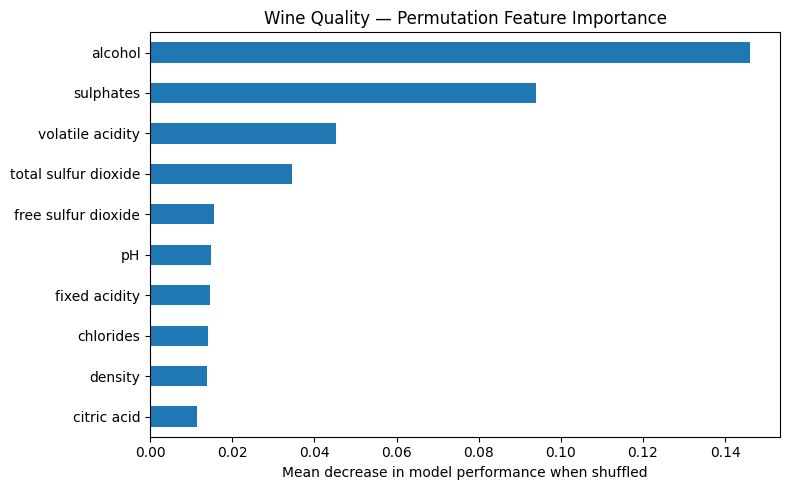

In [30]:
# Select the trained Random Forest model
best_wine_model = wine_results["Random Forest"]["model"]

# Calculate permutation importance on validation data
perm = permutation_importance(
    best_wine_model,
    Xw_valid,
    yw_valid,
    n_repeats=10,
    random_state=42,
    scoring="neg_mean_absolute_error",
    n_jobs=-1
)

# Organize the importance scores
importance = pd.Series(
    perm.importances_mean,
    index=X_w.columns
).sort_values(ascending=False)

print("Top 10 wine features by permutation importance:")
display(importance.head(10).to_frame("Importance"))

# Plot the top 10 features
plt.figure(figsize=(8, 5))
importance.head(10).sort_values().plot(kind="barh")
plt.xlabel("Mean decrease in model performance when shuffled")
plt.title("Wine Quality — Permutation Feature Importance")
plt.tight_layout()
plt.show()

In [31]:
#--PART D--
# Split the breast cancer data
X_train, X_test, y_train, y_test = train_test_split(
    X_c,
    y_c,
    test_size=0.25,
    random_state=42,
    stratify=y_c
)

print("Training shape:", X_train.shape)
print("Test shape:", X_test.shape)
print("\nTraining target distribution:")
print(y_train.value_counts())

Training shape: (426, 30)
Test shape: (143, 30)

Training target distribution:
diagnosis
0    267
1    159
Name: count, dtype: int64


In [32]:
# Create the SVM pipeline
svm_pipeline = Pipeline([
    ("scale", StandardScaler()),
    ("model", SVC())
])

# Define the hyperparameter combinations to test
param_grid = {
    "model__kernel": ["linear", "rbf"],
    "model__C": [0.1, 1, 10, 100],
    "model__gamma": ["scale", 0.01, 0.1]
}

# Five-fold stratified cross-validation
svm_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Search for the best settings using ROC AUC
search = GridSearchCV(
    svm_pipeline,
    param_grid,
    cv=svm_cv,
    scoring="roc_auc",
    n_jobs=-1,
    refit=True
)

print("SVM pipeline and grid search configured.")
print("Parameter combinations:", 2 * 4 * 3)
print("Cross-validation folds:", 5)

SVM pipeline and grid search configured.
Parameter combinations: 24
Cross-validation folds: 5


In [33]:
# Train and tune the SVM
search.fit(X_train, y_train)

# Evaluate the best model on the unseen test set
best_svm = search.best_estimator_
y_pred = best_svm.predict(X_test)
y_score = best_svm.decision_function(X_test)

print("Best parameters:", search.best_params_)
print("Best CV ROC AUC:", round(search.best_score_, 3))
print("Test accuracy:", round(accuracy_score(y_test, y_pred), 3))
print("Test ROC AUC:", round(roc_auc_score(y_test, y_score), 3))

Best parameters: {'model__C': 10, 'model__gamma': 0.01, 'model__kernel': 'rbf'}
Best CV ROC AUC: 0.995
Test accuracy: 0.979
Test ROC AUC: 0.997


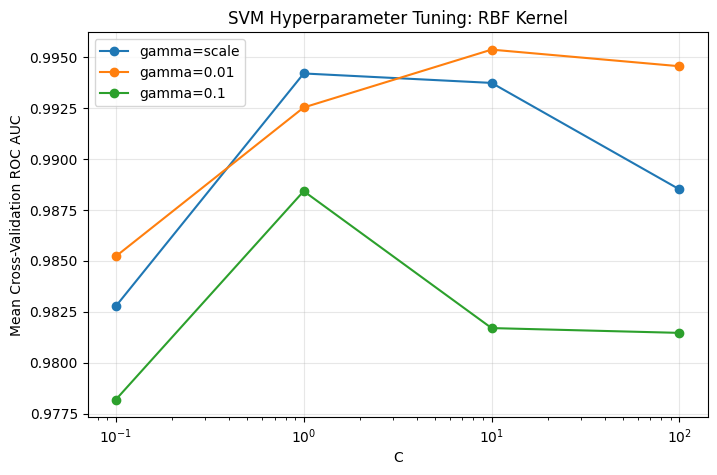

In [34]:
# Convert the grid search results into a DataFrame
results_df = pd.DataFrame(search.cv_results_)

# Keep only RBF kernel results
rbf_results = results_df[
    results_df["param_model__kernel"] == "rbf"
]

# Plot the results
plt.figure(figsize=(8, 5))

for gamma in ["scale", 0.01, 0.1]:
    subset = rbf_results[
        rbf_results["param_model__gamma"] == gamma
    ].sort_values("param_model__C")

    plt.plot(
        subset["param_model__C"].astype(float),
        subset["mean_test_score"],
        marker="o",
        label=f"gamma={gamma}"
    )

plt.xscale("log")
plt.xlabel("C")
plt.ylabel("Mean Cross-Validation ROC AUC")
plt.title("SVM Hyperparameter Tuning: RBF Kernel")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

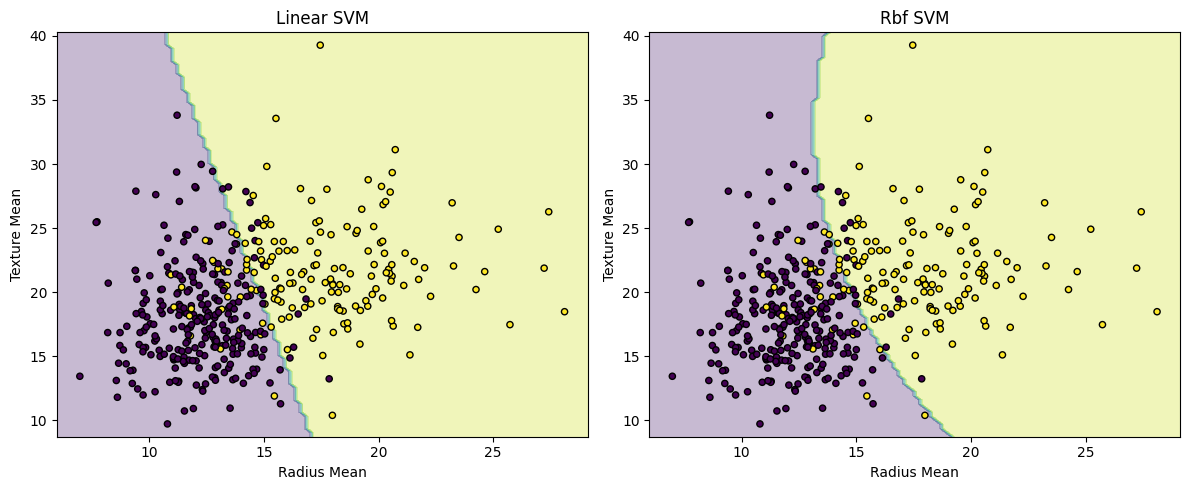

In [35]:
# Select two features for visualization
two = ["radius_mean", "texture_mean"]

X2_train = X_train[two]
X2_test = X_test[two]

# Compare linear and RBF SVMs
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, kernel in zip(axes, ["linear", "rbf"]):
    model_2d = Pipeline([
        ("scale", StandardScaler()),
        ("model", SVC(
            kernel=kernel,
            C=search.best_params_["model__C"],
            gamma=(
                search.best_params_["model__gamma"]
                if kernel == "rbf"
                else "scale"
            )
        ))
    ])

    model_2d.fit(X2_train, y_train)

    DecisionBoundaryDisplay.from_estimator(
        model_2d,
        X2_train,
        response_method="predict",
        alpha=0.3,
        ax=ax
    )

    ax.scatter(
        X2_train["radius_mean"],
        X2_train["texture_mean"],
        c=y_train,
        edgecolors="black",
        s=20
    )

    ax.set_title(f"{kernel.capitalize()} SVM")
    ax.set_xlabel("Radius Mean")
    ax.set_ylabel("Texture Mean")

plt.tight_layout()
plt.show()

In [36]:
# Save the best SVM model
model_path = MODELS / "breast_cancer_svm.joblib"

joblib.dump(search.best_estimator_, model_path)

# Load the saved model
loaded_model = joblib.load(model_path)

# Verify that predictions remain the same
original_predictions = search.best_estimator_.predict(X_test)
loaded_predictions = loaded_model.predict(X_test)

print("Saved model to:", model_path)
print(
    "Predictions identical after reload:",
    np.array_equal(original_predictions, loaded_predictions)
)


Saved model to: /content/UTP-MACHINE-LEARNING/models/breast_cancer_svm.joblib
Predictions identical after reload: True
